In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import Normalize, ListedColormap

fronts = xr.load_dataset(
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/data/fronts/62985.nc"
)

seaice = xr.load_dataset(
    "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/data/fronts/sic_climatology_stats_sh_1991-2020.nc"
)
seaice_mmean = seaice.mmean


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.colors import Normalize, ListedColormap


# ============================================================
# HELPERS: Orsi fronts plotting (handles 0..360 lon, NaNs, dateline jumps)
# ============================================================

def lon360_to_lon180(lon):
    lon = np.asarray(lon)
    return ((lon + 180) % 360) - 180

def plot_front_line(ax, lon, lat, *, jump_deg=20, **plot_kwargs):
    lon = np.asarray(lon).astype(float)
    lat = np.asarray(lat).astype(float)

    m = np.isfinite(lon) & np.isfinite(lat)
    lon = lon[m]
    lat = lat[m]

    lon = lon360_to_lon180(lon)
    if lon.size < 2:
        return

    dlon = np.abs(np.diff(lon))
    breaks = np.where(dlon > jump_deg)[0] + 1
    idxs = np.concatenate(([0], breaks, [lon.size]))

    for a, b in zip(idxs[:-1], idxs[1:]):
        if b - a < 2:
            continue
        ax.plot(lon[a:b], lat[a:b], transform=ccrs.PlateCarree(), **plot_kwargs)


# ============================================================
# HELPERS: Sea-ice seasonal MAX mask (ice-only fill, no contours)
# ============================================================

SEASON_TO_MONTHS = {
    "DJF": [12, 1, 2],
    "MAM": [3, 4, 5],
    "JJA": [6, 7, 8],
    "SON": [9, 10, 11],
}

def seasonal_max_from_monthly_clim(seaice_mmean, season):
    months = SEASON_TO_MONTHS[season]
    return seaice_mmean.sel(month=months).max("month", skipna=True)

ICE_CMAP = ListedColormap(["#601ef9"])  # soft purple

def plot_ice_mask_seasonal_max_iceonly(
    ax, seaice_mmean, season, *, threshold_percent=15.0, alpha=0.35, zorder=12
):
    sic_max = seasonal_max_from_monthly_clim(seaice_mmean, season)

    lon2d = sic_max["lon"].values
    lat2d = sic_max["lat"].values

    ice = (sic_max.values >= threshold_percent)
    ice_only = np.where(ice, 1.0, np.nan)

    ax.pcolormesh(
        lon2d, lat2d, ice_only,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap=ICE_CMAP,
        vmin=0, vmax=1,
        alpha=alpha,
        zorder=zorder
    )


# ============================================================
# DATA PREP: read a prediction matrix and standardize to:
#   longitude, latitude, season, value
# ============================================================

def month_to_season_sh(m):
    m = int(m)
    if m in (12, 1, 2):  return "DJF"
    if m in (3, 4, 5):   return "MAM"
    if m in (6, 7, 8):   return "JJA"
    if m in (9, 10, 11): return "SON"
    return np.nan

def _pick_first_present(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def load_prediction_matrix_as_seasonal_df(csv_path, *, value_col=None):
    df = pd.read_csv(csv_path)

    lon_col = _pick_first_present(df, ["longitude", "lon_center", "lon", "LONGITUDE", "LON", "x", "XC", "xc"])
    lat_col = _pick_first_present(df, ["latitude", "lat_center", "lat", "LATITUDE", "LAT", "y", "YC", "yc"])
    if lon_col is None or lat_col is None:
        raise ValueError(f"Missing lon/lat columns in {csv_path}. Columns: {list(df.columns)}")

    season_col = _pick_first_present(df, ["season", "SEASON"])
    month_col  = _pick_first_present(df, ["month", "MONTH", "mon", "MON"])

    if season_col is None:
        if month_col is None:
            raise ValueError(f"Missing season/month in {csv_path}. Columns: {list(df.columns)}")
        df["season"] = df[month_col].apply(month_to_season_sh)
        season_col = "season"

    if value_col is None:
        value_col = _pick_first_present(
            df,
            ["ensemble_pco2_pred"]
        )
        if value_col is None:
            exclude = {lon_col, lat_col, season_col}
            if month_col is not None:
                exclude.add(month_col)
            numeric_cols = [c for c in df.columns if c not in exclude and pd.api.types.is_numeric_dtype(df[c])]
            if not numeric_cols:
                raise ValueError(f"Could not infer prediction column in {csv_path}. Columns: {list(df.columns)}")
            value_col = numeric_cols[0]

    out = pd.DataFrame({
        "longitude": df[lon_col].astype(float),
        "latitude": df[lat_col].astype(float),
        "season": df[season_col].astype(str),
        "value": df[value_col].astype(float),
    }).dropna(subset=["longitude", "latitude", "season", "value"])

    return out, value_col


# ============================================================
# PLOTTING FUNCTION (4 SEASONS) — fixed pCO2 range
# ============================================================

def plot_seasonal_maps_fixed_range(
    df_seasonal,
    title_prefix,
    output_path,
    *,
    fronts=None,
    seaice_mmean=None,
    ice_threshold_percent=15.0,
    ice_alpha=0.35,
    point_size=10
):
    season_order  = ["DJF", "MAM", "JJA", "SON"]
    season_labels = {"DJF": "Summer", "MAM": "Autumn", "JJA": "Winter", "SON": "Spring"}
    panel_letters = ["a", "b", "c", "d"]

    # Fixed absolute pCO2 range
    norm = Normalize(vmin=350, vmax=450)
    cmap = "Reds"

    vals = df_seasonal["value"].values
    true_max = np.nanmax(vals)
    true_min = np.nanmin(vals)

    fig, axs = plt.subplots(
        2, 2,
        figsize=(10, 10),
        dpi=300,
        subplot_kw={"projection": ccrs.SouthPolarStereo()}
    )
    fig.subplots_adjust(hspace=0.08, wspace=0.08)
    axs = axs.flatten()

    for i, (ax, season) in enumerate(zip(axs, season_order)):
        ax.set_extent([-180, 180, -90, -30], crs=ccrs.PlateCarree())

        ax.coastlines(resolution="110m", linewidth=0.6)
        ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
        ax.gridlines(draw_labels=False, linewidth=0.2, color="gray", alpha=0.5)

        df_s = df_seasonal[df_seasonal["season"] == season]

        sc = ax.scatter(
            df_s["longitude"],
            df_s["latitude"],
            c=df_s["value"],
            s=point_size,
            cmap=cmap,
            norm=norm,
            transform=ccrs.PlateCarree(),
            zorder=2
        )

        # Sea-ice mask in autumn, winter, and spring
        if seaice_mmean is not None and season in ["MAM", "JJA", "SON"]:
            plot_ice_mask_seasonal_max_iceonly(
                ax, seaice_mmean, season,
                threshold_percent=ice_threshold_percent,
                alpha=ice_alpha,
                zorder=12
            )

        # Polar Front
        if fronts is not None:
            plot_front_line(
                ax,
                fronts["LonPF"].values,
                fronts["LatPF"].values,
                jump_deg=20,
                linewidth=1.0,
                linestyle="--",
                color="k",
                zorder=15
            )

        ax.add_feature(cfeature.LAND, facecolor="none", edgecolor="none", zorder=8)
        ax.gridlines(draw_labels=False, linewidth=0.2, color="gray", alpha=0.5, zorder=9)
        ax.coastlines(resolution="110m", linewidth=0.6, zorder=10)

        ax.text(
            0, 1.05,
            f"{panel_letters[i]}) {season_labels[season]}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=11,
        )

    # ============================================================
    # COLORBAR
    # ============================================================
    cax = fig.add_axes([0.215, 0.06, 0.60, 0.018])
    cbar = fig.colorbar(sc, cax=cax, orientation="horizontal", extend="both")
    cbar.set_label(title_prefix)

    # Left and right min/max labels
    cbar.ax.text(
        -0.07, 0.45, f"{true_min:.1f}",
        transform=cbar.ax.transAxes,
        va="center",
        ha="right",
        fontsize=9
    )

    cbar.ax.text(
        1.07, 0.45, f"{true_max:.1f}",
        transform=cbar.ax.transAxes,
        va="center",
        ha="left",
        fontsize=9
    )

    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

## SOCAT ONLY

In [3]:
csv_path = "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/pco2_prediction_matrix_SOCAT_only_MCensemble.csv"
df_seasonal, used_value_col = load_prediction_matrix_as_seasonal_df(csv_path)

In [4]:
df_seasonal.value.median()

np.float64(369.4091)

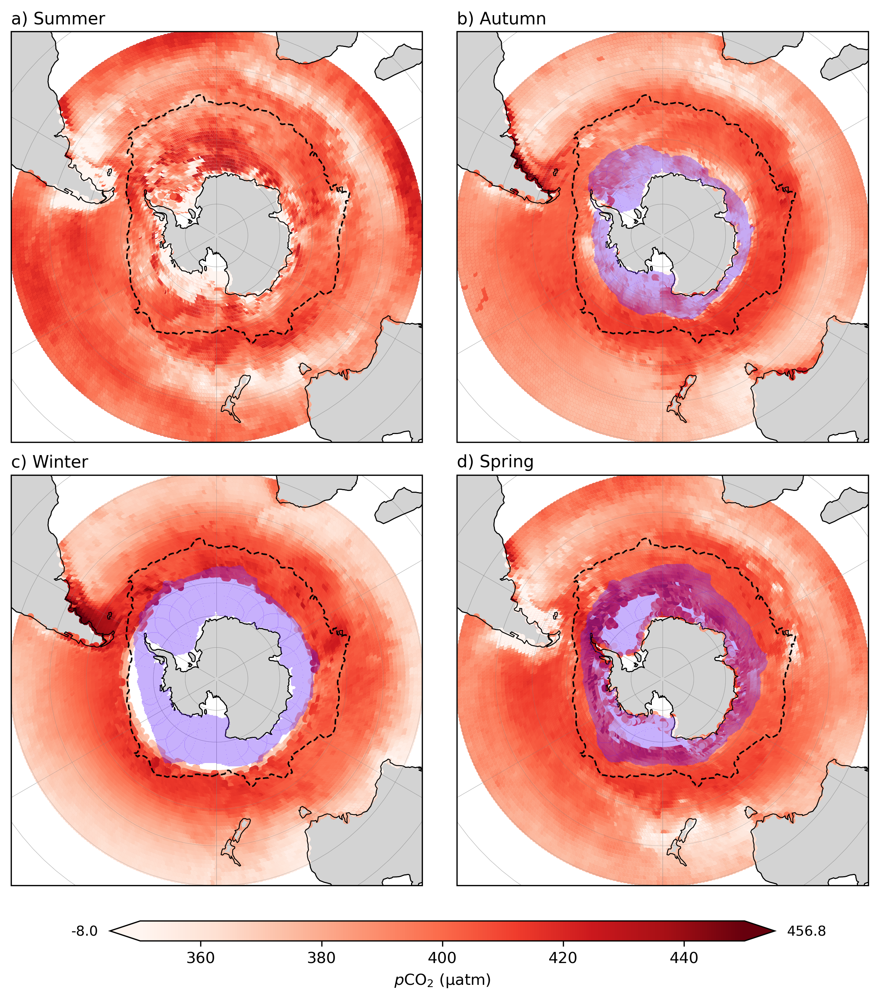

In [5]:
plot_seasonal_maps_fixed_range(
    df_seasonal,
    title_prefix=rf"$p$CO$_2$ (µatm)",
    output_path="/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/Supp_figure_pco2_SOCAT_only_seasonal.png",
    fronts=fronts,
    seaice_mmean=seaice_mmean,
    ice_threshold_percent=15.0,
    ice_alpha=0.35
)

## FLOATS ONLY

In [6]:
csv_path = "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/pco2_prediction_matrix_FLOATS_only_MCensemble.csv"
df_seasonal, used_value_col = load_prediction_matrix_as_seasonal_df(csv_path)

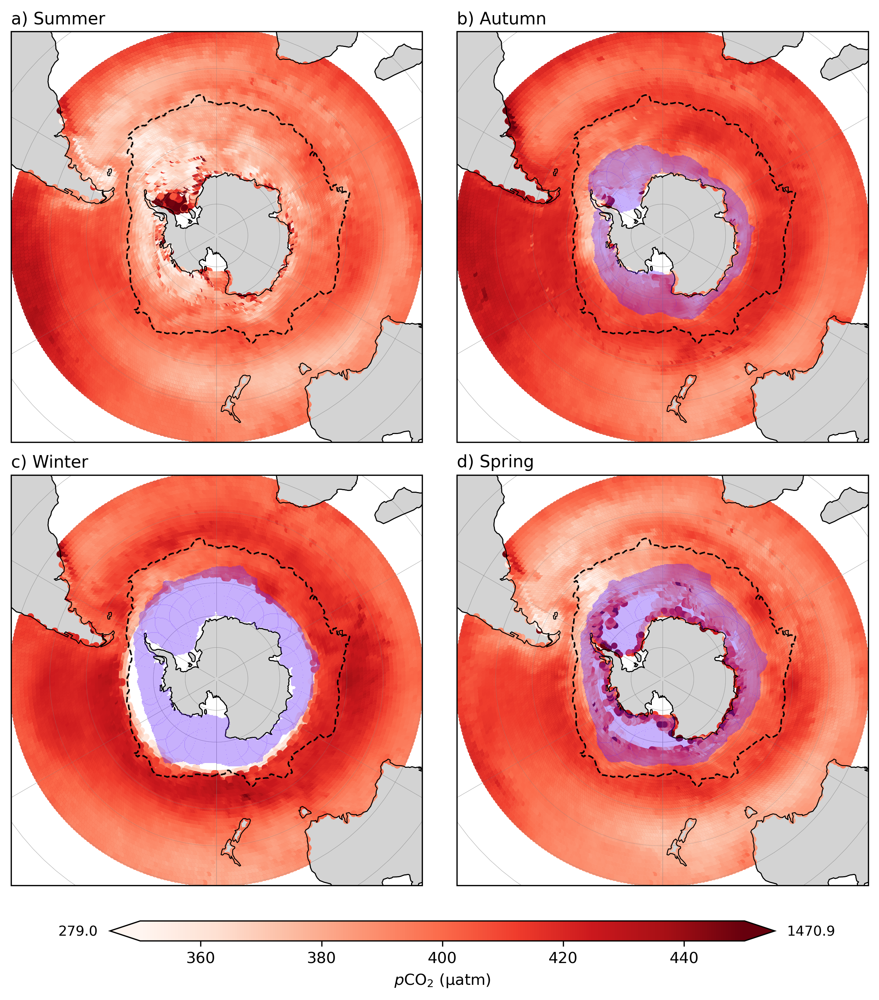

In [7]:
plot_seasonal_maps_fixed_range(
    df_seasonal,
    title_prefix=rf"$p$CO$_2$ (µatm)",
    output_path="/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/Supp_figure_pco2_FLOATS_only_seasonal.png",
    fronts=fronts,
    seaice_mmean=seaice_mmean,
    ice_threshold_percent=15.0,
    ice_alpha=0.35
)


## SOCAT+FLOATS WEIGHTED

In [8]:
csv_path = "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/pco2_prediction_matrix_SOCAT_AND_FLOATS_weighted_MCensemble.csv"
df_seasonal, used_value_col = load_prediction_matrix_as_seasonal_df(csv_path)

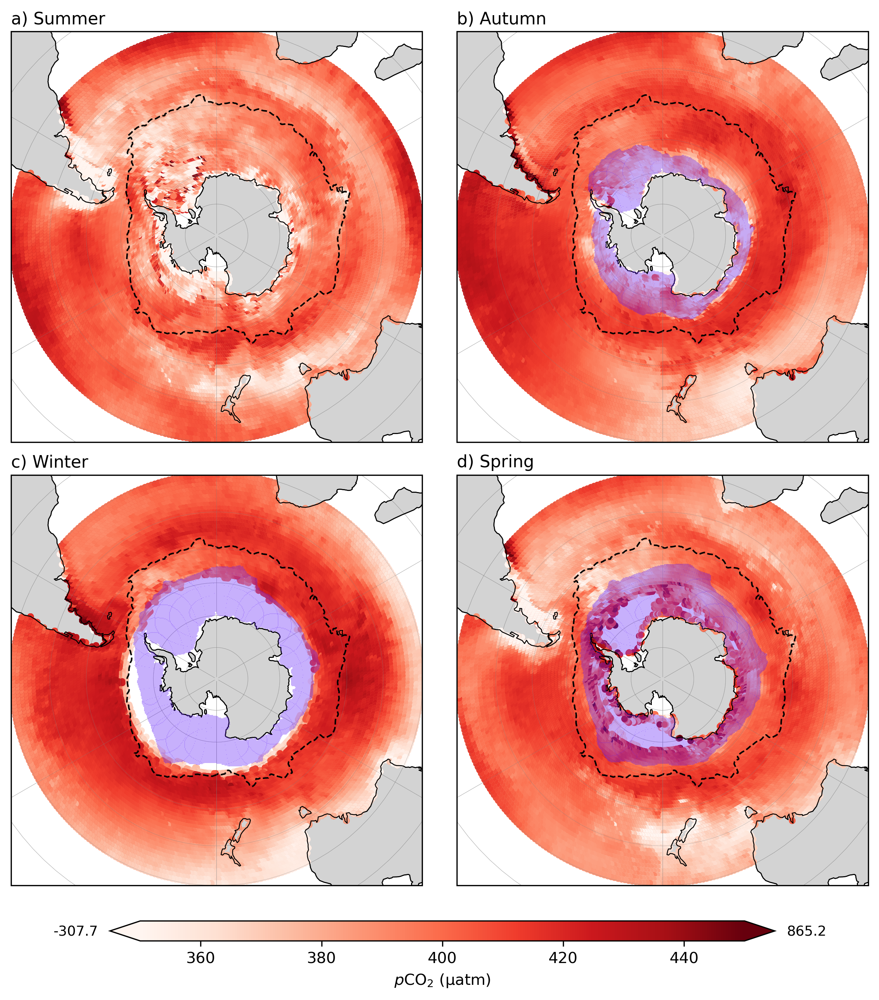

In [9]:
plot_seasonal_maps_fixed_range(
    df_seasonal,
    title_prefix=rf"$p$CO$_2$ (µatm)",
    output_path="/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/Supp_figure_pco2_SOCAT_FLOATS_weighted_seasonal.png",
    fronts=fronts,
    seaice_mmean=seaice_mmean,
    ice_threshold_percent=15.0,
    ice_alpha=0.35
)


## FLOATS SUMMER ONLY

In [10]:
csv_path = "/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/pco2_prediction_matrix_FLOATS_SUMMER_only_MCensemble.csv"
df_seasonal, used_value_col = load_prediction_matrix_as_seasonal_df(csv_path)

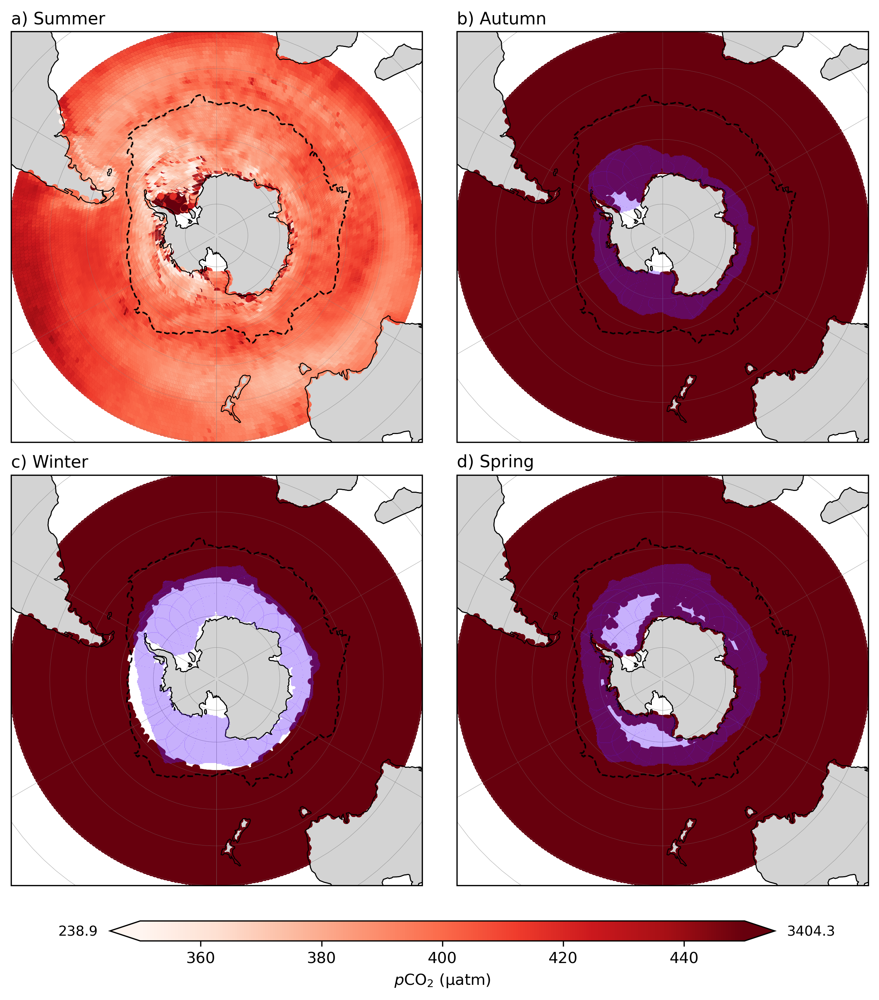

In [11]:
plot_seasonal_maps_fixed_range(
    df_seasonal,
    title_prefix=rf"$p$CO$_2$ (µatm)",
    output_path="/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/Supp_figure_pco2_FLOATS_SUMMER_only_seasonal.png",
    fronts=fronts,
    seaice_mmean=seaice_mmean,
    ice_threshold_percent=15.0,
    ice_alpha=0.35
)
